# Templated lead optimisation for STAT3

STAT3-27(SD-965)-CRBN has good prediction NWHM scores and exp. DC50. This notebook uses the id 27 prediction
(`QQGBHHGKESADLH-JEACGVKKSA-N`, DC50 0.14 uM) as a boltz **structure template**, fine-tunes the
LinkInvent agent with reinforcement, then samples and clusters the fine-tuned agent.

**This notebook is a DEMO.** The RL run uses 2 stages with `batch_size = 2` and one step per stage, so
only 4 SMILES are scored by boltz in total. A real run needs `batch_size = 10` and tens of steps per
stage (or maybe more). The sampling step keeps the normal `num_smiles = 200`.

The template is a soft prior: it biases the protein backbone toward the round-1 PPI orientation, it
does not lock it, and it carries no ligand coordinates. See the final cell for caveats.


## Step 1 Prepare structure, sequences and MSAs

Same preparation as the head of `precompute_stat3.py`.


In [1]:
from pathlib import Path
import os,sys,shutil

workspace=Path.cwd().resolve()
repo_root=next((path for path in (workspace,*workspace.parents)
                if (path/'detect_pocket.py').is_file()),None)
lead_dir=repo_root/'benchmark'/'STAT3'/'lead27_optimization'
stat3_dir=lead_dir.parent
sys.path.insert(0,str(repo_root))
reinvent_env=os.environ.copy()
reinvent_env['PYTHONPATH']=os.pathsep.join(
    path for path in (str(repo_root),reinvent_env.get('PYTHONPATH','')) if path)
os.environ.setdefault('BOLTZ_CACHE','/root/autodl-tmp/boltz/')  # change to your boltz cache dir
from pymol import cmd
import pandas as pd
from detect_pocket import get_pocket_info_from_pdb_info, clean_structure
from util import get_a3m, update_uniprot_ptm_info, update_uniprot_uid2seq, idxmap_boltz2uniprot

pdbid_stat3='6njs'
stat3_cif=lead_dir/f'{pdbid_stat3}.cif'
if not stat3_cif.exists():
    source_cif=stat3_dir/f'{pdbid_stat3}.cif'
    if source_cif.exists():
        shutil.copy2(source_cif,stat3_cif)
    else:
        cmd.reinitialize()
        cmd.fetch(pdbid_stat3,name=pdbid_stat3,type='cif',path=str(lead_dir))
clean_structure(pdbid_stat3,'KQV','A','A',str(lead_dir))
stat3_seq,stat3_pocket=get_pocket_info_from_pdb_info(pdbid_stat3,'KQV','A','A',str(lead_dir),4)

get_a3m(stat3_seq,str(lead_dir/pdbid_stat3))
shutil.copy2(lead_dir/f'{pdbid_stat3}.a3m',lead_dir/'stat3.a3m')

df_resi2evidence=update_uniprot_ptm_info('P40763')
df_uid2seq=update_uniprot_uid2seq(['P40763'])
seq_uniprot=df_uid2seq[df_uid2seq['UniprotID']=='P40763']['seq'].iloc[0]
idxmap=idxmap_boltz2uniprot(stat3_seq,seq_uniprot)
print('POI sequence',len(stat3_seq),'aa; pocket residues (boltz numbering)',sorted(stat3_pocket))

POI sequence 562 aa; pocket residues (boltz numbering) [483, 485, 486, 487, 494, 509, 510, 511, 512, 513, 514, 518, 531, 532, 533, 540]


In [2]:
os.environ

environ{'AgentHost': '172.26.1.203',
        'AutoDLContainerMonitorSetting': '',
        'AutoDLContainerUUID': '5a814bbe65-64fea749',
        'AutoDLDataCenter': 'chongqingDC1',
        'AutoDLRegion': 'cq-A1',
        'AutoDLService6006URL': 'https://u739580-be65-64fea749.cqa1.seetacloud.com:8443',
        'AutoDLService6008URL': 'https://uu739580-be65-64fea749.cqa1.seetacloud.com:8443',
        'AutoDLServiceURL': 'https://u739580-be65-64fea749.cqa1.seetacloud.com:8443',
        'AutodlAutoPanelToken': 'FT*iG4cnlW+*oiZhgDccntfX7ppaccpS18s6Qrt9elLQf/cjHoinJpIDono0d1TcqfHVbQrejpzh*OrSaCf+4qPQ4l0c8GA4Okz*rRwuEkkYjXQ1a3jkfQKSUveydRyc*+0ySC4RrFBtqEOOIHoTka',
        'CONDA_DEFAULT_ENV': 'boltz',
        'CONDA_EXE': '/home/regen/ana/bin/conda',
        'CONDA_PREFIX': '/home/regen/ana/envs/boltz',
        'CONDA_PREFIX_1': '/home/regen/ana',
        'CONDA_PROMPT_MODIFIER': '(boltz) ',
        'CONDA_PYTHON_EXE': '/home/regen/ana/bin/python',
        'CONDA_SHLVL': '2',
        'HOME': 

## Step 2 Build the boltz template from the round-1 prediction

`*_model_0.cif` keeps the metadata that the boltz
template parser needs, but its ligand chain leads to error. `write_boltz_template_cif` drops every non-`P`/`E` chain.

Do not use a PyMOL-saved `*_uni.cif` here: it lacks of metadata.

In [3]:
from util import write_boltz_template_cif

model_0=(stat3_dir/'boltz_results_6njs_crbn_QQGBHHGKESADLH-JEACGVKKSA-N_ternary/predictions/'
         '6njs_crbn_QQGBHHGKESADLH-JEACGVKKSA-N_ternary/'
         '6njs_crbn_QQGBHHGKESADLH-JEACGVKKSA-N_ternary_model_0.cif')
template_cif=write_boltz_template_cif(str(model_0),out_cif=str(lead_dir/'stat3_id27_template.cif'))
print('template:',template_cif)

template: /home/regen/git_develop/potential_linker/benchmark/STAT3/lead27_optimization/stat3_id27_template.cif


## Step 3 Collect the pocket and PPI constraints in boltz numbering

The pocket residue info comes from PDB experimental sources, while PPI and template info comes from the predicted SD-965 ternary.

In [4]:
from Bio.PDB import MMCIFParser
from detect_pocket import search_clean_ppi
from reinvent_plugins.components.boltz_interface import POCKET_CRBN

st=MMCIFParser(auth_chains=True,auth_residues=True,QUIET=True).get_structure('round1',model_0)
identity={res.id[1]:res.id[1] for chain in st[0] for res in chain}
contact_ppi,_,_=search_clean_ppi(st,'P','L','E',identity,identity)

pocket_poi=sorted(stat3_pocket)   # POI-ligand pocket of the 6njs reference structure
pocket_e3=sorted(POCKET_CRBN)     # default CRBN pocket

print('contact_ppi pairs',len(contact_ppi))
print('pocket_poi',len(pocket_poi),'pocket_e3',len(pocket_e3))
assert contact_ppi, 'no POI-E3 contact pair within 6 A in the round-1 prediction'

contact_ppi pairs 72
pocket_poi 16 pocket_e3 9


## Step 4 Prepare the warheads and the RL config

The config below mirrors `boltz_fgfr4_crbn.toml`. Differences:

* `contact_ppi` and the template fields are new optional `Parameters` of the scoring component.
* The early stop score 0.56 is the NWHM score of STAT3-27-CRBN.
* Only trains 2 smiles * 2 steps.

In [5]:
import json


rl_toml=lead_dir/'boltz_stat3_27_temp_crbn.toml'
ppi_toml=json.dumps([[int(poi_resid),int(e3_resid)] for poi_resid,e3_resid in contact_ppi])
pocket_toml=json.dumps([int(resid) for resid in pocket_poi])
template_abs=str(Path(template_cif).resolve())
prior_abs=str(repo_root/'reinvent_prior'/'linkinvent_transformer_pubchem.prior')

warheads_smi=str(lead_dir/'boltz_stat3_crbn_warhead.smi')
poi_name='stat3'
e3_name='crbn'
early_stop_score=0.56 # STAT3-27-CRBN score 
template_toml=f'''
run_type = "staged_learning"
device = "cuda:0"
tb_logdir = "{lead_dir}/tb_logs"
json_out_config = "{lead_dir}/_temp_staged_learning.json"
[parameters]

summary_csv_prefix = "{lead_dir}/{poi_name}_{e3_name}_learning"
use_checkpoint = true
purge_memories = false

## LinkInvent
prior_file = '{prior_abs}'
agent_file = '{prior_abs}'
smiles_file = '{warheads_smi}'

batch_size = 2          # should be 10
unique_sequences = true
randomize_smiles = true
tb_isim = false

[learning_strategy]
  type = "dap" 
  sigma = 128
  rate = 0.0001


[diversity_filter] 
  type = "IdenticalMurckoScaffold"
  bucket_size = 25 
  minscore = 0.4 
  minsimilarity = 0.4
  penalty_multiplier = 0.5


  ### Stage 1
[[stage]]

chkpt_file = '{lead_dir}/boltz_{poi_name}_27_{e3_name}.chkpt'
termination = "simple"
max_score = {early_stop_score}  # terminate if this total score is exceeded
min_steps = 1  # should be 10
max_steps = 2  # should be 20

[stage.scoring]
type = "geometric_mean"

[[stage.scoring.component]]
[stage.scoring.component.BoltzScore]
[[stage.scoring.component.BoltzScore.endpoint]]
name = "docking with boltz"
weight = 1
params.poi_name='{poi_name}'
params.poi_seq='{stat3_seq}'
params.poi_pocket= {stat3_pocket}
# params.is_covalent_poi = true
# params.lig_poi_part ='N(c1c(c(cc(c1))C)Nc1nc2c(cn1)cc(cc2)c1c(Cl)c(OC)cc(OC)c1Cl)C(=O)CC'
# params.lig_warhead_smarts='[C:1]-C-C=O'
# params.covalent_resid_can= 104
# params.covalent_res_atomname='SG'

# params.is_covalent_e3 = false
# params.lig_e3_part = ''
# params.lig_e3_warhead_smarts = ''
# params.covalent_resid_e3_can = 0
# params.covalent_res_atomname_e3 = 'SG'
params.contact_ppi = {ppi_toml}
params.template_cif_or_path = '{template_abs}'
params.template_chain_poi_can = 'P'
params.template_chain_e3_can = 'E'
params.e3_name='{e3_name}'
params.calculate_path='{lead_dir}'
params.generate_bestcif=true
params.w_lgkd=1
params.w_d2=1
params.w_clash=1
'''

with open(rl_toml,'w') as f:
    f.write(template_toml)

## Step 5 Fine-tune the agent with RL (DEMO)

In [12]:
rl_log=lead_dir/'stat3_crbn_learning.log'

# Run step 4 first: it writes rl_toml and warheads_smi.
# reinvent imports reinvent_plugins only when a scorer is built, so the repo root must be on
# sys.path for the RL stages. The env-assignment prefix works in both fish and bash.
# Run this in a terminal with the boltz env activated, then continue with the next cell.
print('PYTHONPATH='+str(repo_root)+' reinvent -l '+str(rl_log)+' '+str(rl_toml))

PYTHONPATH=/home/regen/git_develop/potential_linker reinvent -l /home/regen/git_develop/potential_linker/benchmark/STAT3/lead27_optimization/stat3_crbn_learning.log /home/regen/git_develop/potential_linker/benchmark/STAT3/lead27_optimization/boltz_stat3_27_temp_crbn.toml


## Step 6 Sample linkers

`reinvent` sampling ignores the seed, so repeated runs differ.

In [14]:
sampling_toml=lead_dir/'boltz_stat3_crbn_sample.toml'
with open(sampling_toml,'w') as f:
    f.write(f'''run_type = "sampling"
device = "cuda:0"   # set "cpu" when no GPU is available
json_out_config = "{lead_dir}/stat3_crbn_sampling.json"

[parameters]
model_file = '{lead_dir}/boltz_stat3_27_crbn.chkpt'   # agent written by the last RL stage
smiles_file = '{warheads_smi}'
output_file = '{lead_dir}/stat3_crbn_sampling.csv'
num_smiles = 200
unique_molecules = true
randomize_smiles = false
''')
sample_log=lead_dir/'stat3_crbn_sample.log'

# Sampling builds no scoring component unless the toml defines [filter], so PYTHONPATH is not
# needed here. Reuse the same terminal and run this command after the RL stages finish.
print('reinvent -s 0 -l '+str(sample_log)+' '+str(sampling_toml))


reinvent -s 0 -l /home/regen/git_develop/potential_linker/benchmark/STAT3/lead27_optimization/stat3_crbn_sample.log /home/regen/git_develop/potential_linker/benchmark/STAT3/lead27_optimization/boltz_stat3_crbn_sample.toml


## Step 7 Cluster the sampled linkers

In [17]:
from rdkit.Chem import rdRascalMCES, MolFromSmiles

samples=pd.read_csv(lead_dir/'stat3_crbn_sampling.csv',header='infer')
samples['Linker']=(samples['Linker']
                   .str.replace('[*]','[Po]',1)
                   .str.replace('[*]','[Es]',1))
samples['mol']=samples['Linker'].apply(MolFromSmiles)

# DEMO: cluster only the first 20 linkers, a full run compares every pair of linkers.
# Delete the head(20) line to cluster all sampled linkers, as FGFR4.ipynb does.
samples=samples.head(20).reset_index(drop=True)
cluster_mols=rdRascalMCES.RascalCluster(samples['mol'])

samples['cluster']=-1
for cluster_id,cluster_indices in enumerate(cluster_mols):
    for idx in cluster_indices:
        samples.loc[idx,'cluster']=cluster_id
samples.sort_values(['cluster','NLL']).to_csv(lead_dir/'sampling_clustered.csv',
    index=False,columns=[c for c in samples.columns if c!='mol'])
samples.groupby('cluster')['NLL'].mean().sort_values()

[09:59:20] Too many matching bond pairs (1006) so can't continue.
[09:59:20] Too many matching bond pairs (1157) so can't continue.


cluster
0     6.256667
1    11.465000
2    15.655333
Name: NLL, dtype: float64

In [18]:
samples['NLL_mean']=samples.groupby('cluster')['NLL'].transform('mean')
top_samples=(samples.sort_values('NLL')
                    .drop_duplicates('cluster',keep='first')
                    .sort_values('NLL_mean'))
top_samples.to_csv(lead_dir/'sampling_clustered_top.csv',index=False)
top_samples[['SMILES','NLL','cluster','NLL_mean']].head(10)

,SMILES,NLL,cluster,NLL_mean
6,CS(=O)(=O)c1cccc(OC[C@H](CCC(N)=O)NC(=O)[C@@H]...,4.14,0,6.256667
15,CS(=O)(=O)c1cccc(OC[C@H](CCC(N)=O)NC(=O)[C@@H]...,7.26,1,11.465000
16,C[C@@H]1CN(C(=O)N2CCN3c4ccc5c(c4OC[C@H]3C2)CN(...,4.38,2,15.655333


## Step 8 Show the cluster representatives

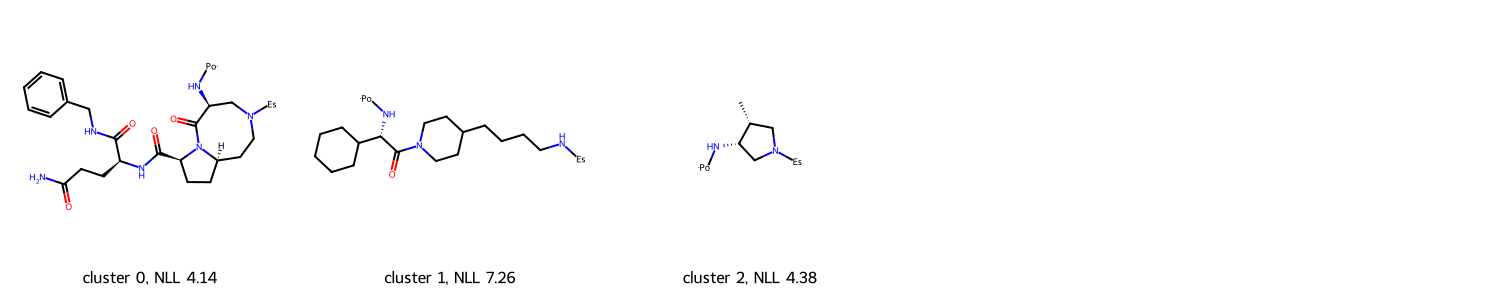

In [19]:
from rdkit.Chem import Draw

TOP_N=5   # DEMO: draw the 5 best cluster representatives
pics_dir=lead_dir/'pics'/'stat3_linker'
pics_dir.mkdir(parents=True,exist_ok=True)
show=top_samples.head(TOP_N).copy()
for row in show.itertuples():
    Draw.MolToImage(row.mol,size=(300,300)).save(pics_dir/f'cluster_{row.cluster}.png')
Draw.MolsToGridImage(show['mol'].tolist(),molsPerRow=TOP_N,
    legends=[f'cluster {c}, NLL {n:.2f}' for c,n in zip(show['cluster'],show['NLL'])],
    subImgSize=(300,300))

## Step 9 Inspect the best ternary

The `_uni.cif` and `.pse` are written next to the prediction; open the `.pse` in PyMOL for the Ub/lys
distance, clash atoms and reference alignment.


In [20]:
from reinvent_plugins.components.comp_boltz_fgfr4 import calculate_one_affinity_score
from util import (cif_boltz2uniprot, e3_uniprot_sequence, generate_pymol_pse,
                  read_boltz_chain_sequence, smi2inchikey)

# DEMO: only the best cluster representative goes through boltz.
best=top_samples.iloc[0]
nwhm,metrics=calculate_one_affinity_score(
    best['SMILES'],'stat3',stat3_seq,pocket_poi,'crbn',
    output_path=str(lead_dir),msa_path=str(lead_dir),
    contact_ppi=contact_ppi,
    template_cif_or_path=template_cif,
    template_chain_poi_can='P',template_chain_e3_can='E',
    is_covalent_poi=False,
    extract_from_precomputed=False,
)
print(f'cluster {best["cluster"]}, NWHM {nwhm:.3f}, {metrics}')

best_cif=lead_dir/f'stat3_crbn_{smi2inchikey(best["SMILES"])}_ternary_best.cif'
best_yaml=str(best_cif).replace('_best.cif','.yaml')
cif_boltz2uniprot(str(best_cif),stat3_seq,seq_uniprot,
                  read_boltz_chain_sequence(best_yaml,'E'),e3_uniprot_sequence('crbn'))
lys_site_uniprot=idxmap.get(int(metrics['closest_lys_resid']),-1)
if lys_site_uniprot>0:
    generate_pymol_pse(str(best_cif)[:-4]+'_uni.cif',lys_site_uniprot,
                       str(lead_dir/'clean'/'6njs_ref.cif'),'resi 580-670',
                       ref_cif_e3=str(repo_root/'data'/'PDB'/'clean'/'8rqa_ref.cif'))
else:
    print('closest lys cannot be mapped to uniprot, pse generation skipped')

Seed set to 0
  0%|          | 0/1 [00:00<?, ?it/s]

MSA server enabled: https://api.colabfold.com
MSA server authentication: no credentials provided
Checking input data.
Processing 1 inputs with 1 threads.


100%|██████████| 1/1 [00:03<00:00,  3.59s/it]
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Running structure prediction for 1 input.


/home/regen/ana/envs/boltz/lib/python3.11/site-packages/pytorch_lightning/utilities/migration/utils.py:56: The loaded checkpoint was produced with Lightning v2.5.0.post0, which is newer than your current Lightning version: v2.5.0
You are using a CUDA device ('NVIDIA GeForce RTX 4080 SUPER') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting DataLoader 0:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

/home/regen/ana/envs/boltz/lib/python3.11/site-packages/pytorch_lightning/utilities/migration/utils.py:56: The loaded checkpoint was produced with Lightning v2.5.0.post0, which is newer than your current Lightning version: v2.5.0
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

/home/regen/ana/envs/boltz/lib/python3.11/site-packages/torch/utils/data/_utils/pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at /pytorch/aten/src/ATen/native/Memory.cpp:46.)
  return data.pin_memory(device)
/home/regen/ana/envs/boltz/lib/python3.11/site-packages/torch/utils/data/_utils/pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at /pytorch/aten/src/ATen/native/Memory.cpp:31.)
  return data.pin_memory(device)


Predicting DataLoader 0: 100%|██████████| 1/1 [00:16<00:00,  0.06it/s]
cluster 0, NWHM 0.531, {'lgKd_ternary': -5.647141456604004, 'dist_ub_square': 13.395588411715153, 'dist_ub': 3.6599984169006348, 'num_clash': 26, 'ref_model': 'model2_clean.pdb', 'closest_lys_resid': 559}
